# 2. Quantum: encode, place atoms, apply a pulse

Run [classical](classical_capacity_constrained_clustering.ipynb) first.
Run **all demand vectors in the selected file**: S uses 14 atoms and `emu-sv`;
M uses 45 atoms and `emu-mps`. No classical repair is applied. Core modeling and pulse algorithms remain inline;
experiment bookkeeping and evidence writers are shared.
Fixed numerical examples describe S; live tables and plots use the selected input.

## The idea

A bit is 0 or 1. Each customer gets two assignment bits:
`10` selects vehicle 0, `01` selects vehicle 1; `00` and `11` are invalid.
Extra **slack bits** encode unused capacity.

Each bit becomes one atom: ground state means 0, excited Rydberg state
means 1. Nearby excited atoms interact. Atom positions and laser pulses
define the energy; measurement produces a bitstring (one **shot**).
Low energy is the goal, not a guarantee of a feasible or optimal answer.

### Select inputs

Set `INPUT_FILE` in the parameter cell below to `"seeds_s.json"`, `"seeds_m.json"`, or another compatible JSON file. Use the same setting in all three notebooks. Bare filenames resolve under `track_a/inputs/`; repository-relative and absolute paths also work.
`OUTPUT_DIRECTORY = None` selects the existing `outputs/all_demands/` for the default S file, or `outputs/<input-file-stem>/` for other files. An explicit output path is also supported; mismatched saved inputs are rejected.

In [1]:
INPUT_FILE = "seeds_s.json"
OUTPUT_DIRECTORY = "track_a/outputs/seeds_s_comparison_full"
shots, seed = 256, 0
timeout_seconds = 180
memory_mb = 4096
dt_ns = 10
mps_max_bond_dim = 64
mps_precision = 1e-5

unbalanced_lambda1 = None  # Saved presets: S 0.2; M 0.75. Set a number to override.
unbalanced_lambda2 = None  # Saved presets: S 0.01; M 0.02. Set a number to override.
unbalanced_assignment_penalty = None

variable_reduction_alpha = None
variable_reduction_beta = None


In [2]:
from pathlib import Path
import json
import sys
from time import perf_counter
import numpy as np
import pandas as pd
from IPython.display import display

root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "track_a" / "common" / "instances.py").is_file())
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from track_a.common.instances import Instance, feasible, notebook_inputs
from track_a.common.analysis import fingerprint
from track_a.common.models import Qubo, assignment_view, encoding_layout, bit_layout, bitstring_breakdown, validate_qubo
from track_a.common.evidence import save_target_evidence, save_sample_evidence

input_path, output, instances = notebook_inputs(INPUT_FILE, OUTPUT_DIRECTORY)
print("Input:", input_path, "| output:", output)
print("Tier:", instances[0].tier.upper(), "| N, K, Q:",
      instances[0].n, instances[0].vehicles, instances[0].capacity)
print(f"Processing all {len(instances)} demand vectors:", [i.id for i in instances])

from dataclasses import asdict
from math import ceil, log2
from pulser import AnalogDevice, Pulse, Register, Sequence
from pulser.waveforms import InterpolatedWaveform, RampWaveform
from track_a.common.analysis import plot_evidence
from track_a.common.quantum import EMBEDDING_SWAPS, EmulatorBackend, PulseSettings, backend_for, emulate_sequence

emulator_backend = backend_for(instances[0])
print("Emulator:", f"emu-{emulator_backend}")


Input: /workspaces/duquantum_hack_2026/track_a/inputs/seeds_s.json | output: /workspaces/duquantum_hack_2026/track_a/outputs/seeds_s_comparison_full
Tier: S | N, K, Q: 4 2 7
Processing all 3 demand vectors: ['s-0', 's-1', 's-2']


Emulator: emu-sv


## 1. Store the target score

A **QUBO** is a score containing individual-bit and bit-pair terms.
We store it as $E(z)=z^TQz+C$ with symmetric $Q$.
Thus a pair's coefficient is $2Q_{ab}$, not $Q_{ab}$.
`objective` is still within-vehicle distance, not route length.

In [3]:
def objective(instance: Instance, labels: tuple[int, ...] | list[int]) -> float:
    distances = instance.distances
    return float(sum(distances[i, j] for i in range(instance.n)
                     for j in range(i) if labels[i] == labels[j]))


def canonical(labels: tuple[int, ...] | list[int]) -> tuple[int, ...]:
    mapping: dict[int, int] = {}
    return tuple(mapping.setdefault(k, len(mapping)) for k in labels)

## 2. Add penalties for broken rules (A1)

Let $D=\max(1,\max c_{ij})$, and $s_v=\sum_r2^r y_{vr}$ be unused capacity:
$$E=F/D+P\sum_i(\sum_vx_{iv}-1)^2+
P\sum_v(\sum_i d_ix_{iv}+s_v-Q)^2.$$

### What each symbol means

| Symbol | Meaning |
| --- | --- |
| $N$, $K$ | Number of customers and available vehicles. S: $N=4$, $K=2$; M: $N=10$, $K=3$. |
| $i$, $j$ | Customer indices, from $0$ to $N-1$. |
| $v$ | Vehicle index, from $0$ to $K-1$. |
| $c_{ij}$ | Euclidean distance between customers $i$ and $j$: their pairwise clustering cost. |
| $d_i$ | Demand of customer $i$. |
| $Q$ | Capacity of each vehicle; $Q=7$ for S and $Q=20$ for M. This is not the QUBO matrix. |
| $x_{iv}$ | Binary assignment variable: $1$ if customer $i$ is assigned to vehicle $v$, otherwise $0$. |
| $F$ | Original clustering cost: $F=\sum_v\sum_{i<j}c_{ij}x_{iv}x_{jv}$. Each customer pair in the same vehicle contributes its distance once. |
| $D$ | Distance normalization factor, $\max(1,\max_{i,j}c_{ij})$. Dividing $F$ by $D$ rescales the objective without changing which feasible grouping is best. |
| $r$ | Slack-bit index, starting at $0$. S uses $r=0,1,2$ (weights 1,2,4); M uses $r=0,1,2,3,4$ (weights 1,2,4,8,16). |
| $y_{vr}$ | Binary slack bit $r$ for vehicle $v$. |
| $s_v$ | Unused capacity represented by those bits: $s_v=\sum_r2^r y_{vr}$. For a correct capacity encoding, $s_v=Q-\sum_i d_ix_{iv}$. |
| $U$ | Normalized clustering cost $F/D$ of the known feasible certificate. It is an upper bound on the best feasible normalized cost, not necessarily the optimum. |
| $P$ | Positive penalty weight, chosen as $U+1$; used for both assignment and capacity violations. |
| $E$ | Total target-QUBO energy: normalized clustering cost plus both penalties. It is not the energy of an exact physical atom-array implementation. |

The expansion below also uses these linear-algebra symbols:

| Symbol | Meaning |
| --- | --- |
| $z$ | Vector containing every binary assignment variable $x_{iv}$ and slack variable $y_{vr}$; 14 entries for S or 45 for M. |
| $a$ | Index of an entry in $z$. Since that entry is binary, $z_a^2=z_a$. |
| $w$ | Coefficient vector for one constraint: assignment coefficients are $1$; capacity coefficients are demands $d_i$ and slack weights $2^r$. |
| $t$ | Required right-hand side of that constraint: $1$ for an assignment rule or $Q$ for a capacity rule. |
| $T$ | Transpose notation: $w^Tz$ is the dot product $\sum_a w_a z_a$. |

In the code, `normalization` is $D$, `bound` is $U$, and `weight` is $P$.

Both squares vanish for a legal assignment with correct slack.
Set $P=U+1$, where $U$ is the normalized cost of the feasible certificate.
A broken rule costs at least $P>U$, so every **target** ground state is feasible.
This does not prove that the atom layout or measured samples are exact.

`add_square` expands $P(w^Tz-t)^2$ using $z_a^2=z_a$.
For S, three slack bits per vehicle have weights **1, 2, 4**:
a load of 5 needs slack 2, encoded `010`.

In [4]:
def build_qubo(instance: Instance, penalty: float | None = None) -> Qubo:
    customers, vehicles, capacity = instance.n, instance.vehicles, instance.capacity
    layout = encoding_layout(instance)
    slack_bits, assignment_size, size = layout.slack_width, layout.assignment_size, layout.size
    normalization = max(float(instance.distances.max()), 1.0)
    bound = objective(instance, instance.certificate) / normalization
    weight = bound + 1 if penalty is None else penalty
    if not np.isfinite(weight) or weight <= bound:
        raise ValueError("Penalty must exceed feasible-certificate normalized objective")
    matrix = np.zeros((size, size))
    constant = 0.0

    def add_square(coefficients, target):
        nonlocal constant
        matrix[:] += weight * np.outer(coefficients, coefficients)
        matrix[np.diag_indices(size)] -= 2 * weight * target * coefficients
        constant += weight * target**2

    for i in range(customers):
        for j in range(i):
            for vehicle in range(vehicles):
                a, b = i * vehicles + vehicle, j * vehicles + vehicle
                matrix[a, b] = matrix[b, a] = instance.distances[i, j] / (2 * normalization)
    for customer in range(customers):
        coefficients = np.zeros(size)
        coefficients[customer * vehicles:(customer + 1) * vehicles] = 1
        add_square(coefficients, 1)
    for vehicle in range(vehicles):
        coefficients = np.zeros(size)
        coefficients[vehicle:assignment_size:vehicles] = instance.demands
        coefficients[layout.slack_slice(vehicle)] = 2.0 ** np.arange(slack_bits)
        add_square(coefficients, capacity)
    names = [f"x_{i}_{v}" for i in range(customers) for v in range(vehicles)]
    names += [f"y_{v}_{bit}" for v in range(vehicles) for bit in range(slack_bits)]
    return Qubo(matrix, constant, weight, normalization, slack_bits, names)

In [5]:
example = instances[0]
qubo = build_qubo(example)
display(pd.DataFrame([
    {"tier": tier, "assignment_only": n * k, "textbook_with_slack": n * k + k * ceil(log2(q + 1)),
     "our_total": n * k + k * ceil(log2(q + 1)), "fits_80_atoms": n * k + k * ceil(log2(q + 1)) <= 80}
    for tier, n, k, q in [("S", 4, 2, 7), ("M", 10, 3, 20), ("L", 15, 4, 30)]
]))
print(example.tier.upper(), "penalty:", qubo.penalty, "| variables:", qubo.variable_order)

,tier,assignment_only,textbook_with_slack,our_total,fits_80_atoms
0,S,8,14,14,True
1,M,30,45,45,True
2,L,60,80,80,True


S penalty: 2.508126572372197 | variables: ['x_0_0', 'x_0_1', 'x_1_0', 'x_1_1', 'x_2_0', 'x_2_1', 'x_3_0', 'x_3_1', 'y_0_0', 'y_0_1', 'y_0_2', 'y_1_0', 'y_1_1', 'y_1_2']


## 3. Read the bits

Read left to right: **8 assignment bits | 3 slack bits | 3 slack bits**.
Slack is little-endian: `110` means $1+2=3$, not 6.
`bit_layout` maps every position to its variable and weight.

A grouping is usable when assignment and capacity hold, even if its
measured slack bits are wrong. Target ground-state validation below
requires **both** legal grouping and correct slack.

In [6]:
def decode(instance: Instance, bitstring: str) -> tuple[int, ...] | None:
    layout = encoding_layout(instance)
    if len(bitstring) != layout.size:
        raise ValueError("Bitstring length does not match encoding")
    if set(bitstring) - {"0", "1"}:
        raise ValueError("Nonbinary candidate")
    x = np.array([int(c) for c in bitstring[:layout.assignment_size]])
    x = x.reshape(instance.n, instance.vehicles)
    if not np.all(x.sum(axis=1) == 1):
        return None
    labels = tuple(int(v) for v in x.argmax(axis=1))
    return canonical(labels) if feasible(instance, labels) else None


def residuals(instance: Instance, bitstring: str) -> tuple[list[int], list[int]]:
    decode(instance, bitstring)
    layout = encoding_layout(instance)
    bits = np.array(list(map(int, bitstring)))
    x = bits[:layout.assignment_size].reshape(instance.n, instance.vehicles)
    slack = bits[layout.assignment_size:].reshape(instance.vehicles, layout.slack_width)
    slack = slack @ (2 ** np.arange(layout.slack_width))
    return (x.sum(axis=1) - 1).tolist(), (np.array(instance.demands) @ x + slack - instance.capacity).tolist()

## 4. Verify the target before emulation

For S, score all $2^{14}=16,384$ bitstrings. Every minimum must obey both
constraints, have correct slack and match the exact clustering reference.
For M, never enumerate $2^{45}$ strings: check the analytic penalty bound,
validate every feasible distinct partition, and construct the exact target
ground strings from the optimal partitions and their vehicle relabelings.
The saved validation method states which check was performed.

In [7]:
def validate_small_qubo(instance: Instance, reference: float) -> dict:
    qubo = build_qubo(instance)
    size = len(qubo.variable_order)
    if size > 16:
        raise ValueError("Exhaustive QUBO validation is restricted to small instances")
    bits = ((np.arange(2**size)[:, None] >> np.arange(size)) & 1)
    energies = np.einsum("bi,ij,bj->b", bits, qubo.matrix, bits) + qubo.constant
    ground = np.flatnonzero(np.isclose(energies, energies.min(), atol=1e-8, rtol=0))
    partitions = set()
    for index in ground:
        bitstring = "".join(map(str, bits[index]))
        labels = decode(instance, bitstring)
        assignment, capacity = residuals(instance, bitstring)
        if labels is None or any(assignment + capacity):
            raise AssertionError("Infeasible target QUBO ground state")
        if not np.isclose(objective(instance, labels), reference):
            raise AssertionError("QUBO and constrained optima disagree")
        partitions.add(labels)
    return {"checked_bitstrings": 2**size, "ground_states": len(ground),
            "ground_state_bitstrings": ["".join(map(str, bits[index])) for index in ground],
            "distinct_ground_partitions": len(partitions), "passed": True,
            "minimum_energy": float(energies.min()),
            "validation_method": "exhaustive-bitstrings", "exhaustive_binary_space": True}


def validate_target_qubo(instance: Instance, reference: float) -> dict:
    if encoding_layout(instance).size <= 16:
        return validate_small_qubo(instance, reference)
    return validate_qubo(instance, reference)

In [8]:
target_checks = {}
for instance in instances:
    reference = json.loads((output / "references" / f"{instance.id}.json").read_text())
    if reference["instance_hash"] != fingerprint(asdict(instance)):
        raise ValueError(f"Classical reference does not match {instance.id}")
    target = build_qubo(instance)
    check = validate_target_qubo(instance, reference["clustering"]["cost"])
    target_checks[instance.id] = check
    save_target_evidence(instance, target, check, output)
display(pd.DataFrame([
    {"instance": name, **{key: check[key] for key in
     ("passed", "validation_method", "checked_bitstrings", "ground_states", "minimum_energy")}}
    for name, check in target_checks.items()
]))
display(pd.DataFrame(bit_layout(example, qubo)))

,instance,passed,validation_method,checked_bitstrings,ground_states,minimum_energy
0,s-0,True,exhaustive-bitstrings,16384,2,1.134194
1,s-1,True,exhaustive-bitstrings,16384,2,1.134194
2,s-2,True,exhaustive-bitstrings,16384,2,1.134194


,position_from_left,python_index,variable,kind,customer,vehicle,slack_weight
0,1,0,x_0_0,assignment,0.0,0,NaN
1,2,1,x_0_1,assignment,0.0,1,NaN
2,3,2,x_1_0,assignment,1.0,0,NaN
3,4,3,x_1_1,assignment,1.0,1,NaN
4,5,4,x_2_0,assignment,2.0,0,NaN
5,6,5,x_2_1,assignment,2.0,1,NaN
6,7,6,x_3_0,assignment,3.0,0,NaN
7,8,7,x_3_1,assignment,3.0,1,NaN
8,9,8,y_0_0,slack,NaN,0,1.0
9,10,9,y_0_1,slack,NaN,0,2.0


### Worked S example: grouping -> bits -> QUBO score

The fixed numbers below describe `seeds_s.json`; live code underneath uses
the selected tier, including all three vehicle columns for M.

For S, use the exact grouping from the classical notebook: `customer_labels = [0, 1, 1, 0]`.
This is a known exact target answer, **not a promise that a shot measures it**.

| Customer | Demand | Vehicle 0 bit | Vehicle 1 bit |
|---|---:|---:|---:|
| 0 | 2 | 1 | 0 |
| 1 | 3 | 0 | 1 |
| 2 | 4 | 0 | 1 |
| 3 | 2 | 1 | 0 |

Read rows left to right: `canonical_assignment_bits = 10010110`.
This is the same result as `customer_labels = [0, 1, 1, 0]`, not a different solution.
Loads are 4 and 7, so unused capacities are **3 and 0**.
With slack weights **1, 2, 4**, these are `110` and `000`.
The full string is **`10010110 | 110 | 000`**, without separators in code.

Each customer's two bits sum to 1. Each vehicle has `load + slack = 7`.
Both penalty sums are therefore zero, leaving only normalized compactness:
$$E=\frac{c_{03}+c_{12}}{D}
\approx\frac{80.886853257}{71.316611388}
\approx\mathbf{1.134193727}.$$

For the shipped input the feasibility witness has cost $107.554476685$,
giving $U\approx1.508126572$ and $P=U+1\approx2.508126572$.
A broken integer constraint costs at least $P>U$, ruling it out as a
target ground state. The exhaustive checks above also verify this numerically.

The next cell independently adds the three score components and checks
they equal `bits @ Q @ bits + constant`. If you edit inputs, the cell
recalculates while the worked numbers above still describe the shipped input.

### Common comparison format

Both notebooks display `customer_labels` (one vehicle number per customer)
and `canonical_assignment_bits` (one bit per customer/vehicle pair):

| `customer_labels` | `canonical_assignment_bits` |
| --- | --- |
| `[0, 1, 1, 0]` | `10010110` |

Grouped by customer: `10010110` = `10 | 01 | 01 | 10`.

These are two encodings of the **same** groups, `{0, 3}` and `{1, 2}`.
`customer_labels` is a label list, not a four-bit QUBO string.
Vehicle names are normalized by first appearance, so swapping vehicle 0 and 1
does not make an equivalent grouping look different. Compare `model_cost`
for solution quality. Raw quantum assignment and slack bits remain separate;
they are never rewritten or repaired for this display.


In [9]:
manual_instance = instances[0]
print("Live hand-check:", manual_instance.id)
manual_reference = json.loads((output / "references" / f"{manual_instance.id}.json").read_text())
manual_labels = tuple(manual_reference["clustering"]["labels"])
manual_target = build_qubo(manual_instance)
assignments = np.array([[int(label == v) for v in range(manual_instance.vehicles)]
                        for label in manual_labels])
loads = np.array(manual_instance.demands) @ assignments
slack = manual_instance.capacity - loads
bits = assignments.ravel().tolist()
for value in slack:
    bits.extend((int(value) >> bit) & 1 for bit in range(manual_target.slack_bits))
manual_bitstring = "".join(map(str, bits))
display(pd.DataFrame({
    "customer": range(manual_instance.n), "demand": manual_instance.demands,
    **{f"vehicle_{v}_bit": assignments[:, v] for v in range(manual_instance.vehicles)},
}))
display(pd.DataFrame({"vehicle": range(manual_instance.vehicles), "load": loads,
                      "slack": slack, "load_plus_slack": loads + slack}))
manual_components = {
    "normalized_compactness": objective(manual_instance, manual_labels) / manual_target.normalization,
    "assignment_penalty": manual_target.penalty * np.sum((assignments.sum(axis=1) - 1)**2),
    "capacity_penalty": manual_target.penalty * np.sum((loads + slack - manual_instance.capacity)**2),
}
manual_energy = sum(manual_components.values())
display(pd.DataFrame([{
    "method": "classical-reference-encoding", **assignment_view(manual_instance, manual_labels),
    "model_cost": objective(manual_instance, manual_labels),
}]))
print("Raw QUBO bits (assignment | slack):",
      bitstring_breakdown(manual_instance, manual_bitstring)["grouped_bitstring"])
print("D:", manual_target.normalization, "| P:", manual_target.penalty)
display(pd.DataFrame([manual_components]))
print("Explicit sum:", manual_energy, "| matrix energy:", manual_target.energy(bits))
assert np.isclose(manual_energy, manual_target.energy(bits))
assert manual_bitstring in target_checks[manual_instance.id]["ground_state_bitstrings"]

Live hand-check: s-0


,customer,demand,vehicle_0_bit,vehicle_1_bit
0,0,2,1,0
1,1,3,0,1
2,2,4,0,1
3,3,2,1,0


,vehicle,load,slack,load_plus_slack
0,0,4,3,7
1,1,7,0,7


,method,customer_labels,canonical_assignment_bits,model_cost
0,classical-reference-encoding,"[0, 1, 1, 0]",10010110,80.886853


Raw QUBO bits (assignment | slack): 10010110 | 110 | 000
D: 71.31661138759598 | P: 2.508126572372197


,normalized_compactness,assignment_penalty,capacity_penalty
0,1.134194,0.0,0.0


Explicit sum: 1.1341937268641564 | matrix energy: 1.134193726864254


## 5. Check device limits

Use the installed `AnalogDevice` limits, not rounded values from the PDF.
Positions: micrometers. Time: nanoseconds. Controls and interactions:
radians per microsecond. Pulser's interaction coefficient already includes
the conversion to angular frequency.

In [10]:
def device_metadata() -> dict:
    channel = AnalogDevice.channels["rydberg_global"]
    actual = {
        "max_atoms": AnalogDevice.max_atom_num,
        "min_separation_um": AnalogDevice.min_atom_distance,
        "max_radius_um": AnalogDevice.max_radial_distance,
        "max_amplitude": channel.max_amp,
        "max_abs_detuning": channel.max_abs_detuning,
        "max_duration_ns": AnalogDevice.max_sequence_duration,
        "interaction_coeff": AnalogDevice.interaction_coeff,
    }
    guide = [80, 5, 38, 12.57, 125.66, 6000, 8.657e5]
    if not all(np.isclose(a, b, rtol=5e-4) for a, b in zip(actual.values(), guide, strict=True)):
        raise RuntimeError(f"Installed AnalogDevice differs from challenge guide: {actual}")
    return {**actual, "guide_discrepancy_beyond_rounding": False,
            "abstract_device": json.loads(AnalogDevice.to_abstract_repr())}

## 6. Place the atoms (A3)

At zero drive the physical energy is
$$E_{\rm atom}=-\delta_f\sum_a z_a+\sum_{a<b}\frac{C_6/\hbar}{r_{ab}^6}z_az_b.$$

Put atoms on a legal triangular grid; try seeded variable swaps to better
match target pair strengths $J=2(Q-\mathrm{diag}(Q))$.
Fit a positive scale $s=\langle J_{\rm real},J\rangle/\|J\|_F^2$.
One global detuning can only fit the **mean** diagonal coefficient.

This is an approximation. Report both errors, retaining unwanted couplings:
$$e_J=\frac{\|J_{\rm real}-sJ\|_F}{\|sJ\|_F},\qquad
e_h=\frac{\|h_{\rm real}-s\,\mathrm{diag}(Q)\|_2}
{\|s\,\mathrm{diag}(Q)\|_2}.$$
Customer coordinates and atom coordinates are different maps.

In [11]:
def embedding(qubo: Qubo, seed: int, swaps: int = EMBEDDING_SWAPS) -> dict:
    """Fit atom permutation on a legal triangular grid, then a positive scale."""
    start = perf_counter()
    device_metadata()
    size = len(qubo.variable_order)
    if size > AnalogDevice.max_atom_num:
        raise ValueError("QUBO exceeds AnalogDevice atom count")
    pairs = 2 * (qubo.matrix - np.diag(np.diag(qubo.matrix)))
    if np.any(pairs < 0):
        raise ValueError("Negative pair couplings are unsupported by repulsive Rydberg interactions")
    candidates = np.array([(i + j / 2, np.sqrt(3) * j / 2)
                           for i in range(-size, size + 1)
                           for j in range(-size, size + 1)])
    candidates = candidates[np.argsort(np.linalg.norm(candidates, axis=1), kind="stable")[:size]]
    coordinates = (candidates - candidates.mean(axis=0)) * 8.0
    radius = np.linalg.norm(coordinates, axis=1).max()
    if radius > 37.9:
        coordinates *= 37.9 / radius
    distances = np.linalg.norm(coordinates[:, None] - coordinates[None, :], axis=-1)
    np.fill_diagonal(distances, np.inf)
    interactions = AnalogDevice.interaction_coeff / distances**6
    rng = np.random.default_rng(seed)
    order = rng.permutation(size)
    norm = np.linalg.norm(pairs)
    if norm == 0:
        raise ValueError("Cannot fit a zero interaction target")

    def score(permutation: np.ndarray) -> float:
        realized = interactions[np.ix_(permutation, permutation)]
        return float(np.sum(realized * pairs))

    best = score(order)
    for _ in range(swaps):
        a, b = rng.choice(size, 2, replace=False)
        order[a], order[b] = order[b], order[a]
        value = score(order)
        if value > best:
            best = value
        else:
            order[a], order[b] = order[b], order[a]
    coordinates = coordinates[order]
    realized = interactions[np.ix_(order, order)]
    scale = float(np.sum(realized * pairs) / norm**2)
    linear = np.diag(qubo.matrix)
    common = float(scale * linear.mean())
    channel = AnalogDevice.channels["rydberg_global"]
    if scale <= 0 or abs(common) > channel.max_abs_detuning:
        raise ValueError("Fitted scale or final global detuning is illegal")
    register = Register(dict(zip(qubo.variable_order, coordinates, strict=True)))
    AnalogDevice.validate_register(register)
    return {
        "variable_order": qubo.variable_order, "coordinates_um": coordinates.tolist(),
        "target_pairs": pairs.tolist(), "realized_pairs": realized.tolist(),
        "target_linear": linear.tolist(), "realized_linear": [common] * size,
        "scale": scale, "constant_offset_scaled": scale * qubo.constant,
        "final_detuning": -common,
        "pair_relative_error": float(np.linalg.norm(realized - scale * pairs) / (scale * norm)),
        "linear_relative_error": float(np.linalg.norm(common - scale * linear) /
                                       np.linalg.norm(scale * linear)),
        "unsupported_coupling_signs": False, "nonquadratic_terms": False,
        "unequal_linear_terms": not np.allclose(linear, linear[0]),
        "seed": seed, "settings": {"algorithm": "triangular-grid-greedy-swaps",
                                   "swap_attempts": swaps, "initial_spacing_um": 8.0},
        "legal": True, "seconds": perf_counter() - start,
    }

In [12]:
layout = embedding(qubo, seed)
print({key: layout[key] for key in
       ("legal", "scale", "pair_relative_error", "linear_relative_error", "final_detuning")})

{'legal': True, 'scale': 0.048542822021241085, 'pair_relative_error': 1.0768493453955446, 'linear_relative_error': 0.3061499463062373, 'final_detuning': 3.5134016350715167}


## 7. Define the laser pulse (A4)

Amplitude ramps **0 → 8 → 0 rad/us**; detuning sweeps from
**-8 rad/us** to the fitted final value. Try durations of 1000 and 2000 ns.
Pulser validates the register, controls and total duration.

In [13]:
def sequence_for(layout: dict, settings: PulseSettings) -> Sequence:
    channel = AnalogDevice.channels["rydberg_global"]
    if (settings.duration_ns % channel.clock_period
            or not channel.min_duration <= settings.duration_ns <= AnalogDevice.max_sequence_duration
            or not 0 < settings.amplitude <= channel.max_amp
            or not -channel.max_abs_detuning <= settings.initial_detuning < 0):
        raise ValueError("Illegal pulse settings")
    register = Register(dict(zip(layout["variable_order"], layout["coordinates_um"], strict=True)))
    AnalogDevice.validate_register(register)
    sequence = Sequence(register, AnalogDevice)
    sequence.declare_channel("drive", "rydberg_global")
    amplitude = InterpolatedWaveform(settings.duration_ns, [0, settings.amplitude, 0])
    detuning = RampWaveform(settings.duration_ns, settings.initial_detuning, layout["final_detuning"])
    sequence.add(Pulse(amplitude, detuning, 0), "drive")
    sequence.measure("ground-rydberg")
    if sequence.get_duration(include_fall_time=True) > AnalogDevice.max_sequence_duration:
        raise ValueError("Pulse including modulation fall time exceeds device duration")
    return sequence

## 8. Run safely on the local emulator

The selected tier determines the backend: **S -> emu-sv**, **M -> emu-mps**.
The parameter cell controls shots, timestep, timeout, address-space limit,
MPS maximum bond dimension and truncation precision. Every executed setting
is recorded. MPS is an approximate tensor-network simulation; its truncation
and timestep convergence are not established by one run.

Qubit-order optimization is disabled to preserve the documented bit order.
Resource failures and emulator errors are explicit; there is no state-vector
fallback for M and no cloud execution.

In [14]:
def emulate(layout: dict, settings: PulseSettings, shots: int, seed: int,
            timeout_seconds: float = 180, memory_mb: int = 4096, *,
            backend: EmulatorBackend = emulator_backend, dt_ns: int = dt_ns,
            mps_max_bond_dim: int = mps_max_bond_dim, mps_precision: float = mps_precision) -> dict:
    result = emulate_sequence(
        sequence_for(layout, settings), shots, seed,
        timeout_seconds=timeout_seconds, memory_mb=memory_mb, backend=backend,
        dt_ns=dt_ns, mps_max_bond_dim=mps_max_bond_dim, mps_precision=mps_precision,
    )
    result["settings"] = {**asdict(settings), **result["settings"]}
    return result

### Judge pulses using clustering only

Count feasible raw shots and their clustering gaps. All shots stay in
the hit-probability denominator; absent feasible shots give an undefined gap.
No routing, depot or CVRP reference is used to select a pulse.

In [15]:
from track_a.common.analysis import clustering_metrics

example_reference = json.loads((output / "references" / f"{example.id}.json").read_text())
print("Before sampling:", clustering_metrics(example, {}, example_reference["clustering"]["cost"]))

Before sampling: {'actual_shots': 0, 'feasible_shots': 0, 'feasibility_rate': None, 'best_model_gap': None, 'best_model_labels': None, 'model_hit_probability_0.1pct': None, 'model_hit_probability_1pct': None, 'model_hit_probability_5pct': None}


## 9. Compare two pulses, then run every demand vector

Calibrate on the first selected instance (`s-0` or `m-0`) only. Rank pulses by best feasible model gap, then
0.1%-hit probability, then feasibility. Freeze the selected controls and
apply them to **every instance**, fitting each instance's layout separately.
The final detuning is derived from that layout; the pulse duration,
peak amplitude and initial detuning are frozen.
Reuse that instance's selected calibration shots rather than counting an extra run.
This is **not held-out validation**. Save raw counts, layout, sequence,
settings and status for every vector; no repair or certificate warm start.

In [16]:
from track_a.common.experiments import quantum_runs

Calibrating S on emu-sv: PulseSettings(duration_ns=1000, amplitude=8.0, initial_detuning=-8.0)
Calibrating S on emu-sv: PulseSettings(duration_ns=2000, amplitude=8.0, initial_detuning=-8.0)
Quantum s-0
Quantum s-1
Quantum s-2
Calibration status: completed | pulse: {'duration_ns': 1000, 'amplitude': 8.0, 'initial_detuning': -8.0}


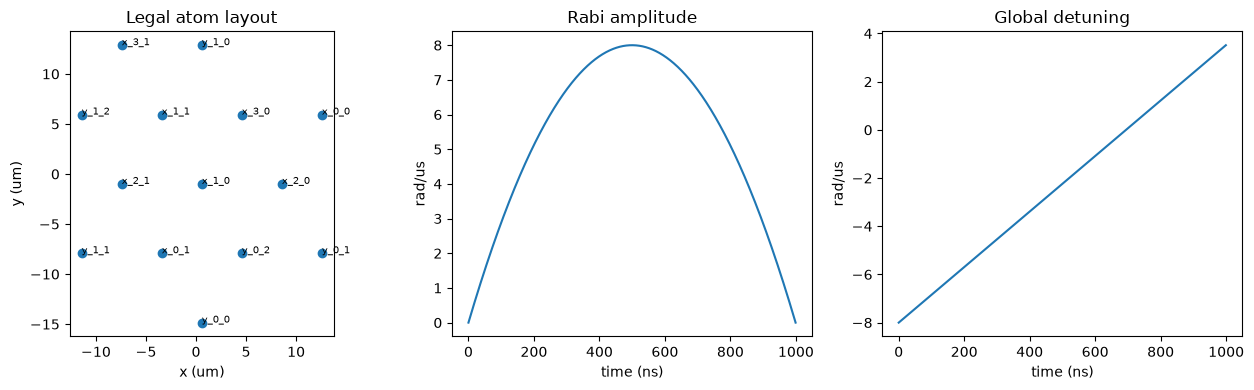

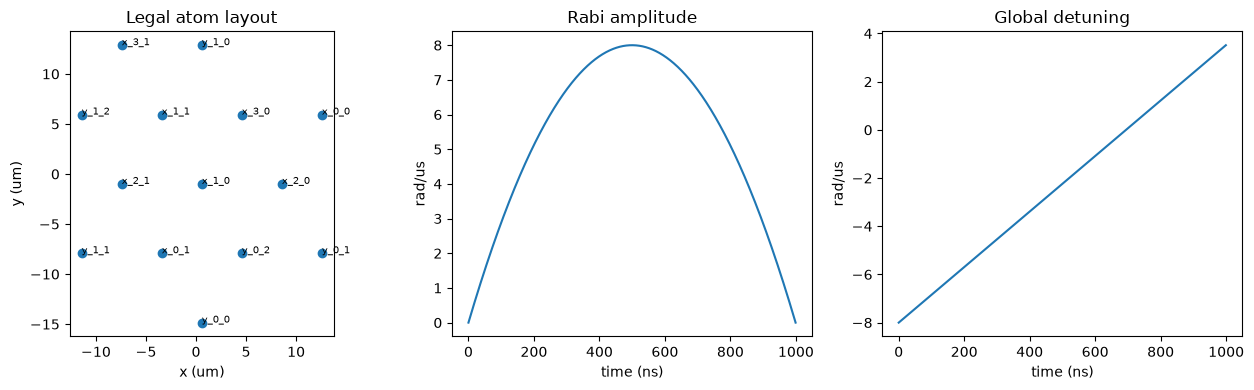

In [17]:
quantum_runs(instances, output, shots, seed, timeout_seconds, memory_mb,
             dt_ns=dt_ns, mps_max_bond_dim=mps_max_bond_dim, mps_precision=mps_precision)
calibration = json.loads((output / "calibration.json").read_text())
print("Calibration status:", calibration["status"], "| pulse:", calibration["selected"])
if calibration["selection_fallback"] is not None:
    print("Warning:", calibration["selection_fallback"])
plot_evidence(output, instances[0].id, seed)

## 10. Separate exact ground states from measured answers

An exact target ground state has the lowest **QUBO** energy.
A lowest-energy measured string is merely the best energy we happened
to sample; it may be infeasible. Neither proves a ground state of the
approximate atom Hamiltonian.

Show exact ground states that were measured, or explicitly report none,
then show the lowest-energy measured strings. Each table includes counts,
feasibility and decoded slack. Save the complete measured table as JSON.

For direct comparison, the final table shows the classical exact answer and
the **best feasible quantum sample** with the same `customer_labels`,
`canonical_assignment_bits` and `model_cost` columns for every instance.
An infeasible sample has no valid decoded comparison assignment; its raw bits
are still retained. Raw strings can also differ only because vehicle names
were swapped, or because their slack bits differ.


In [18]:
sample_summary = []
comparison_rows = []
sample_columns = [
    "customer_labels", "canonical_assignment_bits", "model_cost", "count", "probability",
    "feasible", "exact_target_ground_state", "target_energy",
    "grouped_bitstring", "assignment_bits", "slack_bits",
]
for instance in instances:
    target = build_qubo(instance)
    exact = target_checks[instance.id]
    run_path = output / "runs" / f"{instance.id}-quantum-global-{seed}.json"
    run = json.loads(run_path.read_text())
    evidence = save_sample_evidence(instance, target, exact, run, output)
    summary = evidence["summary"]
    sample_summary.append(summary)
    reference = json.loads((output / "references" / f"{instance.id}.json").read_text())
    comparison_rows.extend([
        {"instance": instance.id, "method": "classical-exact",
         **assignment_view(instance, reference["clustering"]["labels"]),
         "model_cost": reference["clustering"]["cost"], "status": reference["clustering"]["status"]},
        {"instance": instance.id, "method": "quantum-best-feasible",
         **assignment_view(instance, summary["customer_labels"]),
         "model_cost": summary["model_cost"], "status": run["status"]},
    ])
    if run["status"] != "completed":
        print(instance.id, "has no completed quantum samples:", run["status"], evidence["error"])
        continue
    if instance.id == instances[0].id:
        print("Detailed example:", instance.id, "| exact target ground states:", exact["ground_state_bitstrings"])
        if evidence["observed_ground_states"]:
            print("Exact target ground states actually sampled:")
            display(pd.DataFrame(evidence["observed_ground_states"])[sample_columns].rename(
                columns={"assignment_bits": "raw_assignment_bits",
                         "grouped_bitstring": "raw_qubo_bits_with_slack"}))
        else:
            print("No exact target-QUBO ground state was sampled in this run.")
        print("Lowest-target-energy bitstrings actually sampled:")
        display(pd.DataFrame(evidence["lowest_sampled_states"])[sample_columns].rename(
            columns={"assignment_bits": "raw_assignment_bits",
                     "grouped_bitstring": "raw_qubo_bits_with_slack"}))

print("Direct comparison: classical exact vs best feasible quantum sample")
display(pd.DataFrame(comparison_rows))
display(pd.DataFrame(sample_summary))
print("Full per-instance bitstring tables saved in:", output / "groundstates")

Detailed example: s-0 | exact target ground states: ['10010110110000', '01101001000110']
No exact target-QUBO ground state was sampled in this run.
Lowest-target-energy bitstrings actually sampled:


,customer_labels,canonical_assignment_bits,model_cost,count,probability,feasible,exact_target_ground_state,target_energy,raw_qubo_bits_with_slack,raw_assignment_bits,slack_bits
0,None,None,None,1,0.003906,False,False,5.54448,00100101 | 101 | 100,00100101,101100


Direct comparison: classical exact vs best feasible quantum sample


,instance,method,customer_labels,canonical_assignment_bits,model_cost,status
0,s-0,classical-exact,"[0, 1, 1, 0]",10010110,80.886853,proven_optimum
1,s-0,quantum-best-feasible,"[0, 0, 1, 1]",10100101,83.933395,completed
2,s-1,classical-exact,"[0, 1, 1, 0]",10010110,80.886853,proven_optimum
3,s-1,quantum-best-feasible,"[0, 1, 1, 0]",10010110,80.886853,completed
4,s-2,classical-exact,"[0, 1, 1, 0]",10010110,80.886853,proven_optimum
5,s-2,quantum-best-feasible,"[0, 1, 1, 0]",10010110,80.886853,completed


,instance,status,actual_shots,customer_labels,canonical_assignment_bits,model_cost,feasible_shots,exact_ground_shots,lowest_sampled_target_energy
0,s-0,completed,256,"[0, 0, 1, 1]",10100101,83.933395,7,0,5.544480
1,s-1,completed,256,"[0, 1, 1, 0]",10010110,80.886853,5,0,3.176912
2,s-2,completed,256,"[0, 1, 1, 0]",10010110,80.886853,10,0,3.435575


Full per-instance bitstring tables saved in: /workspaces/duquantum_hack_2026/track_a/outputs/seeds_s_comparison/groundstates


## Additional solver: slack-free unbalanced penalization

This is **added alongside** the binary-slack QUBO, not a replacement.
Following the photo's "Optimize H", define each vehicle's capacity headroom as

$$h_k(x)=Q-\sum_{j=0}^{N-1}d_jx_{jk},\qquad h_k(x)\geq0.$$

The assignment variable $x_{jk}\in\{0,1\}$ is 1 when customer $j$ uses vehicle
$k$; $d_j$ is that customer's demand, $Q$ the capacity, $N$ the customer count,
and $K$ the vehicle count. Capacity equality is allowed. The sums in $h_k$
include $x_{jk}$: demand only counts when assigned to this vehicle.

$$H_u(x)=\frac{F(x)}{s}
+\beta\sum_j\left(\sum_kx_{jk}-1\right)^2
+\sum_k\left[-\lambda_1h_k(x)+\lambda_2h_k(x)^2\right].$$

Here $F$ is the same within-vehicle pair-distance cost as before
($\frac12x^\mathsf{T}Dx$ when $D$ repeats the distance matrix by vehicle),
$s=\max(1,\max_{ij}c_{ij})$ is the existing distance normalization, $\beta$ is
the assignment penalty, and $\lambda_1,\lambda_2>0$ are tunable capacity
weights. The matrix convention remains $H_u=x^\mathsf{T}Q_ux+c_u$.
With $L_k=\sum_jd_jx_{jk}$, the capacity term expands to

$$-\lambda_1Q+\lambda_2Q^2
+(\lambda_1-2\lambda_2Q)L_k+\lambda_2L_k^2.$$

Only $NK$ assignment bits are used: **S 8, M 30**, versus **S 14, M 45**
with binary slack. There are no slack or auxiliary bits.

The parameter cell exposes `unbalanced_lambda1`, `unbalanced_lambda2`, and
`unbalanced_assignment_penalty`. `None` for either lambda selects tier-aware
saved presets in `inputs/unbalanced_penalties.json`: **S 0.2 and 0.01**;
**M 0.75 and 0.02**. Numeric overrides remain available.
M was selected using classical SA clustering gaps; this does not establish
quantum-optimal weights or MPS convergence. See the saved tuning evidence
in `outputs/penalty_tuning/m_unbalanced_search.json` for MPS check statuses.
The S weights preserve the exact constrained optimum in all 256-bitstring
checks per instance. At 256 shots and seed 0, optimal quantum hits increased
from 2 to 7 across the three inputs, but feasible shots decreased from 14 to
10. This is benchmark tuning, not a claim of universal sampling improvement.
`None` for the assignment penalty uses the same
certificate-based numeric value as the original solver, but **not its proof**.
The certificate is never a warm start. Use identical weights in both notebooks.

Unlike the original slack penalty, this term is not zero on every feasible
assignment: its minimum occurs at $h=\lambda_1/(2\lambda_2)$. It can change the
preferred feasible grouping, and its ground state can violate constraints.
We therefore check original one-hot and capacity constraints for every raw
sample; no repair is applied. Compare **`model_cost`**, feasibility rates and
gaps to the constrained reference, not $H_u$ against the slack-QUBO energy.


In [19]:
from track_a.common.unbalanced import quantum_unbalanced_runs, comparison_rows as solver_comparison_rows
from track_a.common.models import unbalanced_penalty_weights

effective_lambda1, effective_lambda2 = unbalanced_penalty_weights(
    instances[0], unbalanced_lambda1, unbalanced_lambda2)
print("Effective unbalanced weights:", effective_lambda1, effective_lambda2)

display(pd.DataFrame([
    {"instance": instance.id, "assignment_atoms": instance.n * instance.vehicles,
     "slack_atoms": 0, "backend": f"emu-{backend_for(instance)}"}
    for instance in instances
]))
quantum_unbalanced_runs(
    instances, output, shots, seed, timeout_seconds, memory_mb,
    lambda1=unbalanced_lambda1, lambda2=unbalanced_lambda2,
    assignment_penalty=unbalanced_assignment_penalty,
    dt_ns=dt_ns, mps_max_bond_dim=mps_max_bond_dim, mps_precision=mps_precision,
)
unbalanced_calibration = json.loads((output / "unbalanced" / "calibration.json").read_text())
print("Unbalanced calibration:", unbalanced_calibration["status"],
      "| pulse:", unbalanced_calibration["selected"])
if unbalanced_calibration["selection_fallback"] is not None:
    print("Warning:", unbalanced_calibration["selection_fallback"])
display(pd.DataFrame(solver_comparison_rows(instances, output, seed)))
first_unbalanced = json.loads(
    (output / "samples" / f"{instances[0].id}-quantum-unbalanced-{seed}.json").read_text())
print("Lowest sampled unbalanced energies (not a claim of exact ground states):")
if first_unbalanced["sampled_states"]:
    display(pd.DataFrame(first_unbalanced["sampled_states"]).head(10))
else:
    print(first_unbalanced["status"], first_unbalanced["error"])
print("Unbalanced raw samples:", output / "samples")
print("Separate calibration, embeddings and sequences:", output / "unbalanced")


Effective unbalanced weights: 0.2 0.01


,instance,assignment_atoms,slack_atoms,backend
0,s-0,8,0,emu-sv
1,s-1,8,0,emu-sv
2,s-2,8,0,emu-sv


Calibrating unbalanced S on emu-sv: PulseSettings(duration_ns=1000, amplitude=8.0, initial_detuning=-8.0)
Calibrating unbalanced S on emu-sv: PulseSettings(duration_ns=2000, amplitude=8.0, initial_detuning=-8.0)
Quantum unbalanced s-0: 8 atoms
Quantum unbalanced s-1: 8 atoms
Quantum unbalanced s-2: 8 atoms
Unbalanced calibration: completed | pulse: {'duration_ns': 2000, 'amplitude': 8.0, 'initial_detuning': -8.0}


,instance,method,encoding,customer_labels,canonical_assignment_bits,model_cost,status,outcome,bits,actual_shots,feasible_shots,feasibility_rate,best_model_gap,error,lambda1,lambda2,assignment_penalty
0,s-0,classical-exact,constrained,"[0, 1, 1, 0]",10010110,80.886853,proven_optimum,Exact constrained optimum,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,s-0,classical-qubo-sa,binary-slack-v1,"[0, 1, 1, 0]",10010110,80.886853,completed,Feasible sample found,14.0,256.0,55.0,0.214844,0.000000,NaN,NaN,NaN,2.508127
2,s-0,classical-unbalanced-sa,unbalanced-v1,"[0, 1, 1, 0]",10010110,80.886853,completed,Feasible sample found,8.0,256.0,219.0,0.855469,0.000000,NaN,0.2,0.01,2.508127
3,s-0,quantum-global,binary-slack-v1,"[0, 0, 1, 1]",10100101,83.933395,completed,Feasible sample found,14.0,256.0,7.0,0.027344,3.766423,NaN,NaN,NaN,2.508127
4,s-0,quantum-unbalanced,unbalanced-v1,"[0, 1, 1, 0]",10010110,80.886853,completed,Feasible sample found,8.0,256.0,4.0,0.015625,0.000000,NaN,0.2,0.01,2.508127
5,s-1,classical-exact,constrained,"[0, 1, 1, 0]",10010110,80.886853,proven_optimum,Exact constrained optimum,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,s-1,classical-qubo-sa,binary-slack-v1,"[0, 1, 1, 0]",10010110,80.886853,completed,Feasible sample found,14.0,256.0,51.0,0.199219,0.000000,NaN,NaN,NaN,2.176912
7,s-1,classical-unbalanced-sa,unbalanced-v1,"[0, 1, 1, 0]",10010110,80.886853,completed,Feasible sample found,8.0,256.0,256.0,1.000000,0.000000,NaN,0.2,0.01,2.176912
8,s-1,quantum-global,binary-slack-v1,"[0, 1, 1, 0]",10010110,80.886853,completed,Feasible sample found,14.0,256.0,5.0,0.019531,0.000000,NaN,NaN,NaN,2.176912
9,s-1,quantum-unbalanced,unbalanced-v1,"[0, 1, 1, 0]",10010110,80.886853,completed,Feasible sample found,8.0,256.0,4.0,0.015625,0.000000,NaN,0.2,0.01,2.176912


Lowest sampled unbalanced energies (not a claim of exact ground states):


,bitstring,count,probability,target_energy,feasible,customer_labels,canonical_assignment_bits,model_cost,assignment_residuals,capacity_headroom
0,01101001,3,0.011719,0.624194,True,"[0, 1, 1, 0]",10010110,80.886853,"[0, 0, 0, 0]","[0, 3]"
1,01011010,1,0.003906,0.626912,True,"[0, 0, 1, 1]",10100101,83.933395,"[0, 0, 0, 0]","[1, 2]"
2,10010010,7,0.027344,1.492320,False,None,NaN,NaN,"[0, 0, -1, 0]","[3, 4]"
3,01100001,3,0.011719,1.492320,False,None,NaN,NaN,"[0, 0, -1, 0]","[4, 3]"
4,10000110,2,0.007812,1.622320,False,None,NaN,NaN,"[0, -1, 0, 0]","[3, 3]"
5,10100001,6,0.023438,2.046812,False,None,NaN,NaN,"[0, 0, -1, 0]","[2, 5]"
6,01010010,1,0.003906,2.046812,False,None,NaN,NaN,"[0, 0, -1, 0]","[5, 2]"
7,01001010,1,0.003906,2.096354,False,None,NaN,NaN,"[0, -1, 0, 0]","[1, 5]"
8,10010001,3,0.011719,2.123374,False,None,NaN,NaN,"[0, 0, -1, 0]","[5, 2]"
9,01100010,2,0.007812,2.123374,False,None,NaN,NaN,"[0, 0, -1, 0]","[2, 5]"


Unbalanced raw samples: /workspaces/duquantum_hack_2026/track_a/outputs/seeds_s_comparison/samples
Separate calibration, embeddings and sequences: /workspaces/duquantum_hack_2026/track_a/outputs/seeds_s_comparison/unbalanced


## Additional QUBO: variable_reduction (photographed formula)

As requested, preserve the photo's **minus binary-slack sign**:

$$H_v=F(x)/s+\alpha\sum_k\left(\frac{L_k(x)}{Q}-1-b_k\right)^2
+\beta\sum_j\left(\sum_kx_{jk}-1\right)^2,\quad
L_k(x)=\sum_jd_jx_{jk},\quad b_k\in\{0,1\}.$$

$x_{jk}$ assigns customer $j$ to vehicle $k$, $d_j$ is demand, $Q$ is vehicle
capacity, and $F/s$ is the same normalized compactness objective as before.
$\alpha$ weights normalized capacity residuals and $\beta$ assignment residuals.
The demand sum explicitly includes $x_{jk}$, which is implicit in the photo.

**This retains one binary slack bit per vehicle**, rather than eliminating all
slack: **S 10 bits, M 33 bits**, compared with slack 14/45 and unbalanced 8/30.
It is not an exact encoding of $L_k\le Q$: zero capacity penalty occurs at
$L_k=Q$ or $2Q$, so overcapacity can be favored. Original constraints are checked
independently, without repairing samples. We do not change the photographed
minus sign into the usual positive-slack equality.

Direct expansion gives negative assignment/slack couplings, unsupported by the
repulsive quantum embedding. Use the exact reversible substitution
$b_k=1-z_k$, $z_k\in\{0,1\}$:

$$\left(L_k/Q-1-b_k\right)^2=\left(L_k/Q+z_k-2\right)^2.$$

Both classical and quantum run this same bijectively transformed QUBO.
The physical bit order is customer-major assignment bits followed by
`z_0, ..., z_(K-1)`. Evidence retains the raw physical bits and the logical
`b_k = 1-z_k` values. Complementing auxiliaries is not sample repair.

`variable_reduction_alpha` and `variable_reduction_beta` are independently
configurable. `None` sets each to `1 + certificate_cost / s`, an **untuned
starting value, not a feasibility proof**. Energies of different formulations
are not directly comparable; use original feasible costs, gaps and raw-shot
success rates. The previous solvers and their saved results remain intact.


In [3]:
from track_a.common.variable_reduction import quantum_variable_reduction_runs
from track_a.common.unbalanced import comparison_rows as solver_comparison_rows

display(pd.DataFrame([
    {"instance": instance.id, "assignment_atoms": instance.n * instance.vehicles,
     "complemented_auxiliary_atoms": instance.vehicles,
     "total_atoms": instance.n * instance.vehicles + instance.vehicles,
     "backend": f"emu-{backend_for(instance)}"}
    for instance in instances
]))
quantum_variable_reduction_runs(
    instances, output, shots, seed, timeout_seconds, memory_mb,
    alpha=variable_reduction_alpha, beta=variable_reduction_beta,
    dt_ns=dt_ns, mps_max_bond_dim=mps_max_bond_dim, mps_precision=mps_precision)
photo_calibration = json.loads((output / "variable_reduction" / "calibration.json").read_text())
print("Variable-reduction calibration:", photo_calibration["status"],
      "| pulse:", photo_calibration["selected"])
if photo_calibration["selection_fallback"] is not None:
    print("Warning:", photo_calibration["selection_fallback"])
display(pd.DataFrame(solver_comparison_rows(instances, output, seed)))
photo_samples = json.loads(
    (output / "samples" / f"{instances[0].id}-quantum-variable_reduction-{seed}.json").read_text())
if photo_samples["sampled_states"]:
    print("Lowest sampled target energies (not proven ground states):")
    display(pd.DataFrame(photo_samples["sampled_states"]).head(10))
else:
    print(photo_samples["status"], photo_samples["error"])
print("Variable-reduction embeddings/sequences:", output / "variable_reduction")


,instance,assignment_atoms,complemented_auxiliary_atoms,total_atoms,backend
0,s-0,8,2,10,emu-sv
1,s-1,8,2,10,emu-sv
2,s-2,8,2,10,emu-sv


Calibrating variable_reduction S on emu-sv: PulseSettings(duration_ns=1000, amplitude=8.0, initial_detuning=-8.0)


Calibrating variable_reduction S on emu-sv: PulseSettings(duration_ns=2000, amplitude=8.0, initial_detuning=-8.0)


Quantum variable_reduction s-0: 10 atoms


Quantum variable_reduction s-1: 10 atoms


...

Variable-reduction calibration: completed | pulse: {'duration_ns': 2000, 'amplitude': 8.0, 'initial_detuning': -8.0}


,instance,method,encoding,customer_labels,canonical_assignment_bits,model_cost,status,outcome,bits,actual_shots,feasible_shots,feasibility_rate,best_model_gap,error,lambda1,lambda2,alpha,beta,assignment_penalty
0,s-0,classical-exact,constrained,"[0, 1, 1, 0]",10010110,80.886853,proven_optimum,Exact constrained optimum,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,s-0,classical-qubo-sa,binary-slack-v1,"[0, 1, 1, 0]",10010110,80.886853,completed,Feasible sample found,14.0,256.0,55.0,0.214844,0.000000,NaN,NaN,NaN,NaN,NaN,2.508127
2,s-0,classical-unbalanced-sa,unbalanced-v1,"[0, 1, 1, 0]",10010110,80.886853,completed,Feasible sample found,8.0,256.0,219.0,0.855469,0.000000,NaN,0.2,0.01,NaN,NaN,2.508127
3,s-0,classical-variable_reduction-sa,variable-reduction-complemented-v1,"[0, 1, 1, 0]",10010110,80.886853,completed,Feasible sample found,10.0,256.0,220.0,0.859375,0.000000,NaN,NaN,NaN,2.508127,2.508127,2.508127
4,s-0,quantum-global,binary-slack-v1,"[0, 0, 1, 1]",10100101,83.933395,completed,Feasible sample found,14.0,256.0,7.0,0.027344,3.766423,NaN,NaN,NaN,NaN,NaN,2.508127
5,s-0,quantum-unbalanced,unbalanced-v1,"[0, 1, 1, 0]",10010110,80.886853,completed,Feasible sample found,8.0,256.0,4.0,0.015625,0.000000,NaN,0.2,0.01,NaN,NaN,2.508127
6,s-0,quantum-variable_reduction,variable-reduction-complemented-v1,"[0, 1, 1, 0]",10010110,80.886853,completed,Feasible sample found,10.0,256.0,14.0,0.054688,0.000000,NaN,NaN,NaN,2.508127,2.508127,2.508127
7,s-1,classical-exact,constrained,"[0, 1, 1, 0]",10010110,80.886853,proven_optimum,Exact constrained optimum,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,s-1,classical-qubo-sa,binary-slack-v1,"[0, 1, 1, 0]",10010110,80.886853,completed,Feasible sample found,14.0,256.0,51.0,0.199219,0.000000,NaN,NaN,NaN,NaN,NaN,2.176912
9,s-1,classical-unbalanced-sa,unbalanced-v1,"[0, 1, 1, 0]",10010110,80.886853,completed,Feasible sample found,8.0,256.0,256.0,1.000000,0.000000,NaN,0.2,0.01,NaN,NaN,2.176912


Lowest sampled target energies (not proven ground states):


,bitstring,count,probability,target_energy,feasible,customer_labels,canonical_assignment_bits,model_cost,assignment_residuals,capacity_headroom,physical_auxiliary_bits,logical_binary_slack,normalized_capacity_residuals
0,0110100111,3,0.011719,1.594870,True,"[0, 1, 1, 0]",10010110,80.886853,"[0, 0, 0, 0]","[0, 3]",11,"[0, 0]","[0.0, -0.428571]"
1,1001011011,1,0.003906,1.594870,True,"[0, 1, 1, 0]",10010110,80.886853,"[0, 0, 0, 0]","[3, 0]",11,"[0, 0]","[-0.428571, 0.0]"
2,0110010111,1,0.003906,2.185284,False,None,NaN,NaN,"[0, 0, 0, 0]","[4, -1]",11,"[0, 0]","[-0.571429, 0.142857]"
3,0100100111,2,0.007812,3.563673,False,None,NaN,NaN,"[0, -1, 0, 0]","[3, 3]",11,"[0, 0]","[-0.428571, -0.428571]"
4,1001010111,1,0.003906,3.737876,False,None,NaN,NaN,"[0, 0, 0, 0]","[5, -2]",11,"[0, 0]","[-0.714286, 0.285714]"
5,0101100011,2,0.007812,3.822233,False,None,NaN,NaN,"[0, 0, 0, -1]","[3, 2]",11,"[0, 0]","[-0.428571, -0.285714]"
6,1010010011,1,0.003906,3.822233,False,None,NaN,NaN,"[0, 0, 0, -1]","[2, 3]",11,"[0, 0]","[-0.285714, -0.428571]"
7,0001100111,1,0.003906,3.898796,False,None,NaN,NaN,"[-1, 0, 0, 0]","[3, 2]",11,"[0, 0]","[-0.428571, -0.285714]"
8,0010010111,5,0.019531,3.906520,False,None,NaN,NaN,"[-1, 0, 0, 0]","[4, 1]",11,"[0, 0]","[-0.571429, -0.142857]"
9,0110000111,4,0.015625,3.921977,False,None,NaN,NaN,"[0, 0, -1, 0]","[4, 3]",11,"[0, 0]","[-0.571429, -0.428571]"


Variable-reduction embeddings/sequences: /workspaces/duquantum_hack_2026/track_a/outputs/seeds_s_comparison_full/variable_reduction


## Limits

S uses 8 assignment + 6 slack bits; M uses 30 assignment + 15 slack bits.
Those original solvers remain unchanged. The additional unbalanced solver uses only 8 (S) or 30 (M) assignment bits, with no feasibility guarantee. L remains out of scope.
Every selected demand vector is processed, but one geometry is shared and
calibration reuses the first instance. Inputs are explicit rows, not a
seed-based generator (A2). MPS bond-dimension, truncation and timestep
convergence are not established; inspect recorded resource failures and
actual raw-shot feasibility rather than assuming success.
Exact target correctness, embedding error and sampling quality are separate.
No speedup, noise robustness, DMM or QPU claim is made.
Next: [results](results.ipynb).
The photographed variable-reduction alternative uses 10 (S) / 33 (M) bits,
including one complemented binary slack per vehicle; it has no original-constraint guarantee.
